# M00-2 | eval 與 train 模式 export 出來的圖不一樣

同一個 `ConvBnReLU`，呼叫 `model.eval()` 或 `model.train()` 之後再 export，得到的圖不同。
這是後面 M04（fusion）與 M06（QAT）的伏筆：

| 流程 | 模式 | BatchNorm 在圖上 |
|---|---|---|
| PTQ | `model.eval()` 後 export → `prepare_pt2e` | 用 running mean／var，是固定的仿射變換，可以直接折進 conv |
| QAT | `model.train()` 後 export → `prepare_qat_pt2e` | 要算這個 batch 的統計量並更新 running stats，必須留在圖上 |

- **A.** 兩種模式各 export 一次，看圖差在哪。
- **B.** `batch_norm` node 的參數差在哪；export 之後還能不能切換模式。

In [1]:
import torch
from torch.export import export

from common.graph_utils import diff_ops
from common.models import example_inputs, get_model
from common.pt2e import quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. 兩種模式各 export 一次

In [2]:
def export_in_mode(train: bool):
    model = get_model("conv_bn_relu")
    model.train() if train else model.eval()
    return export(model, example_inputs()).module()


gm_eval = export_in_mode(train=False)
gm_train = export_in_mode(train=True)
table(diff_ops(gm_eval, gm_train, "gm_eval", "gm_train", tablefmt="html"))

op,gm_eval,gm_train,delta
add_,0,1,1
batch_norm,1,1,0
conv2d,1,1,0
relu,1,1,0


op 的種類幾乎一樣，只有 train 多了一個 `add_`。把兩張圖上下排列（參數也畫出來）：

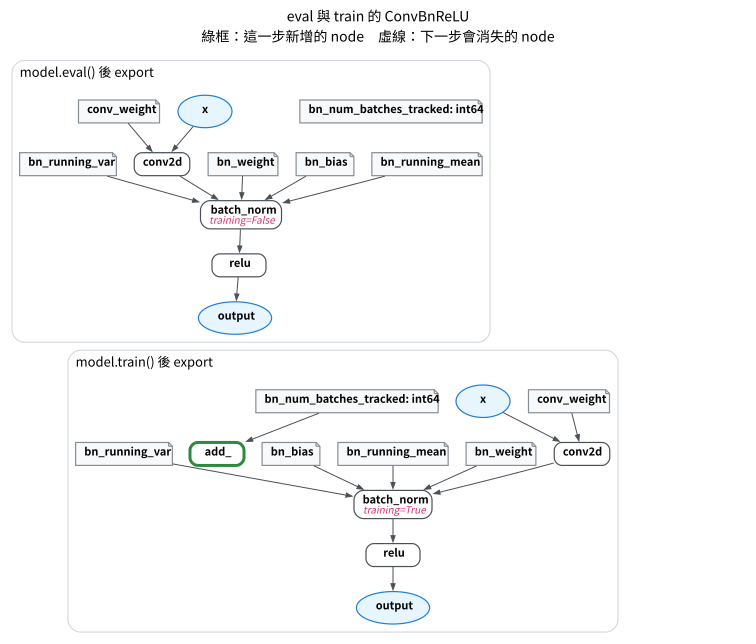

In [3]:
def bn_node(gm):
    return next(n for n in gm.graph.nodes if n.op == "call_function" and "batch_norm" in str(n.target))


BN_ARG_NAMES = ["input", "weight", "bias", "running_mean", "running_var",
                "training", "momentum", "eps", "cudnn_enabled"]
notes = [{"batch_norm": f"training={bn_node(gm).args[BN_ARG_NAMES.index('training')]}"}
         for gm in (gm_eval, gm_train)]
draw_stages([(gm_eval, "model.eval() 後 export"), (gm_train, "model.train() 後 export")],
            show_params=True, notes=notes, per_row=1, title="eval 與 train 的 ConvBnReLU")

- 資料流（conv2d → batch_norm → relu）兩邊一樣，`batch_norm` 也是同一個 op `aten.batch_norm.default`。差別藏在它的 `training` 參數裡（標在 node 底下）。
- train 多出的 `add_`（綠框）讀 `bn_num_batches_tracked`：train 模式下 BN 的 forward 會做 `num_batches_tracked += 1`，export 把它記成一個原地修改的 `add_`。
  它沒有任何使用者，output 不依賴它；eval 那邊的 `bn_num_batches_tracked` 則沒有人讀。

In [4]:
add_node = next(n for n in gm_train.graph.nodes if n.op == "call_function" and n.name.startswith("add_"))
print(f"{add_node.name}{tuple(str(a) for a in add_node.args)}，users = {list(add_node.users)}")
assert add_node.args[0].target == "bn.num_batches_tracked" and not add_node.users

add_('bn_num_batches_tracked', '1')，users = []


那 `running_mean`／`running_var` 呢？圖上沒有更新它們的 node，因為更新在 `batch_norm` 這個 op **內部**：
`training=True` 時，它用這個 batch 的統計量正規化，同時把 running stats 原地寫回傳進來的 buffer。
`num_batches_tracked += 1` 則是 `nn.BatchNorm.forward` 呼叫 op 之前自己做的一行 Python，所以單獨成為 `add_`。

## B. `batch_norm` 的參數差在哪

In [7]:
def bn_args(gm):
    return {k: (v.name if isinstance(v, torch.fx.Node) else v) for k, v in zip(BN_ARG_NAMES, bn_node(gm).args)}


ae, at = bn_args(gm_eval), bn_args(gm_train)
table([[k, ae[k], at[k], "✱" if ae[k] != at[k] else ""] for k in BN_ARG_NAMES],
      ["參數", "gm_eval", "gm_train", "不同"])

參數,gm_eval,gm_train,不同
input,conv2d,conv2d,
weight,bn_weight,bn_weight,
bias,bn_bias,bn_bias,
running_mean,bn_running_mean,bn_running_mean,
running_var,bn_running_var,bn_running_var,
training,False,True,✱
momentum,0.1,0.1,
eps,1e-05,1e-05,
cudnn_enabled,False,False,


In [8]:
assert [k for k in BN_ARG_NAMES if ae[k] != at[k]] == ["training"]

九個參數只有 `training` 不同。也就是說，模式在 export 的那一刻就寫死在圖上：`batch_norm` 的 `training` 參數，加上 train 多出的 `add_`。

那 export 之後還能用 `.train()`／`.eval()` 切換嗎？

In [9]:
try:
    gm_eval.train()
    raised = None
except NotImplementedError as e:
    raised = e
print(f"gm_eval.train() → {type(raised).__name__}: {raised}")
assert isinstance(raised, NotImplementedError)

gm_eval.train() → NotImplementedError: Calling train() is not supported yet.


不行。`GraphModule` 的 forward 是由圖產生的程式碼，`.train()` 改不了圖上寫死的參數。
QAT 需要在訓練與評估之間切換時，要用 `move_exported_model_to_train`／`move_exported_model_to_eval`（M06），它們做的事就是改寫圖上這些 node。

## 小結

- export 前先決定 eval 或 train：模式會寫進圖裡（`batch_norm` 的 `training` 參數、train 多出的 `add_`）。
- PTQ 用 eval 模式 export，BN 才能在 `prepare_pt2e` 時折進 conv（M01-1 看過 batch_norm 消失）；QAT 用 train 模式（M04、M06）。
- export 之後的 GraphModule 不能再用 `.train()`／`.eval()` 切換。